# 🚴 千葉県 自転車盗マップ

* **作成者**: [田上達貴]　[白石大策]　[福田直生]

* **作品概要**:
  千葉県警察の自転車盗データ（全10,054件）をもとに、市区町村別の発生状況と時間帯・被害者属性の傾向をインタラクティブなFoliumマップとグラフで可視化したダッシュボードです。レイヤー切り替え、順位（`#`）表示・検索/選択ジャンプ、折りたたみ式まとめパネル、2条件の横並び比較グラフを備えています。

* **データの出典**:
  千葉県警察 自転車盗統計データ（CSV）

* **自分たちで追加した機能や特徴**:
  * 国土地理院APIとローカルキャッシュを活用した市区町村代表座標の取得・再利用。
  * レイヤー切り替え（「1. 全件」「2. 10〜20歳代」「3. 学生層（中・高・大）」）による重なり防止と視認性の向上。
  * ポップアップへの順位バッジ（`#1`〜）および発生件数・無施錠率・被害者の主な年齢・職業の表示。
  * 検索バーとプルダウンによる全地域・`#` 番号の絞り込みおよび該当自治体への自動移動・ポップアップ表示。
  * 「縮小／展開」ボタン付きのまとめパネルと、時間帯区分別の2条件横並び比較グラフ（「施錠有無」「学生層 vs その他」）の実装。

## 数値から見えた発見
1. **無施錠の割合が非常に高い**：千葉県全体の自転車盗10,054件のうち、無施錠（施錠せず）は6,879件（約68.4%）を占めており、鍵をかけないまま駐輪しているケースが目立ちます。
2. **若年層・学生層と帰宅時間帯の集中**：被害者は10〜20歳代が約70.4%（7,075件）、学生層（中・高・大）が約47.1%を占めており、時間帯別では夕方〜帰宅時間帯（16〜19時台）に無施錠での被害が多く発生しています。

## 防犯の提案
* **短時間でも「二重ロック・施錠習慣」を促す啓発と駐輪環境改善**：発生件数が多い自治体（船橋市・市川市・松戸市など）や通学・帰宅動線上の駐輪場・駅周辺で、「ちょっと立ち寄るだけ・短時間だから」という油断を減らす施錠リマインド表示や、地球ロック・補助錠の活用を勧める啓発を行うことが有効です。

* **これから改善したいこと、追加したい機能**:
  * 画面拡大時やノートブック表示環境における地図枠・パネル余白のさらなる最適化。
  * 選択中のレイヤー（10〜20歳代・学生層）に連動した順位（`#`）や検索候補の切り替え対応。

In [ ]:
# 読み込むファイルを設定する（Notebookと同じフォルダに保存）
filename = "bike.csv"
encoding = "cp932"

# 千葉県警のCSVはShift-JIS（CP932）。追加インストールは不要
import csv
with open(filename, encoding=encoding, newline="") as file:
    incidents = list(csv.DictReader(file))

# 1行が1件の事件。件数を確認する
len(incidents)

In [ ]:
import json
import time
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlopen

import folium
import pandas as pd

# ===== 設定エリア =====
CSV_PATH = "bike.csv"
CSV_ENCODING = "cp932"  # 必要に応じて "utf-8-sig" 等に変更
CACHE_PATH = Path("chiba_muni_coords_cache.json")

GSI_API_URL = "https://msearch.gsi.go.jp/address-search/AddressSearch?q="
REQUEST_INTERVAL_SEC = 0.25  # 公開APIへの連続アクセス間隔

CHIBA_CENTER = [35.6074, 140.1233]  # 千葉市中央区付近
DEFAULT_ZOOM = 10
TOP_N_LABELS = 15  # ポップアップ・凡例で目立たせる上位件数

In [ ]:
# 1. CSV読み込み
df = pd.read_csv(CSV_PATH, encoding=CSV_ENCODING)

# 2. for文で市区町村ごとの件数と無施錠件数を集計
stats_by_muni = {}
for _, row in df.iterrows():
    muni = row["市区町村（発生地）"]
    if muni not in stats_by_muni:
        stats_by_muni[muni] = {"count": 0, "unlocked": 0}
    stats_by_muni[muni]["count"] += 1
    if row["施錠関係"] == "施錠せず":
        stats_by_muni[muni]["unlocked"] += 1

summary_rows = []
for muni, s in stats_by_muni.items():
    cnt = s["count"]
    unl = s["unlocked"]
    summary_rows.append({
        "市区町村": muni,
        "件数": cnt,
        "無施錠件数": unl,
        "無施錠率(%)": round(unl / cnt * 100, 1) if cnt > 0 else 0.0,
    })

summary_df = (
    pd.DataFrame(summary_rows)
    .sort_values("件数", ascending=False)
    .reset_index(drop=True)
)

# 3. 国土地理院APIから座標を取得（キャッシュがあれば再利用）
coords_cache = {}
if CACHE_PATH.exists():
    coords_cache = json.loads(CACHE_PATH.read_text(encoding="utf-8"))

def fetch_gsi_latlon(query_text: str):
    """国土地理院APIから (lat, lon) を取得。見つからなければ None。"""
    url = GSI_API_URL + quote(query_text)
    with urlopen(url, timeout=10) as res:
        data = json.loads(res.read().decode("utf-8"))
    if not data:
        return None
    # GSI APIのgeometry.coordinatesは [lon, lat] 順
    lon, lat = data[0]["geometry"]["coordinates"]
    return float(lat), float(lon)

lat_list = []
lon_list = []
for muni in summary_df["市区町村"]:
    cache_key = f"千葉県{muni}"
    if cache_key not in coords_cache:
        try:
            latlon = fetch_gsi_latlon(cache_key)
        except Exception as e:
            print(f"取得失敗 ({cache_key}): {e}")
            latlon = None
        coords_cache[cache_key] = latlon
        time.sleep(REQUEST_INTERVAL_SEC)

    latlon = coords_cache[cache_key]
    lat_list.append(latlon[0] if latlon else None)
    lon_list.append(latlon[1] if latlon else None)

# キャッシュ保存
CACHE_PATH.write_text(
    json.dumps(coords_cache, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

summary_df["lat"] = lat_list
summary_df["lon"] = lon_list

print("座標取得完了:", summary_df["lat"].notna().sum(), "/", len(summary_df))
summary_df.head(10)

In [ ]:
m = folium.Map(
    location=CHIBA_CENTER,
    zoom_start=DEFAULT_ZOOM,
    tiles="https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png",
    attr="OpenStreetMap",
)

max_count = summary_df["件数"].max()

for idx, row in summary_df.dropna(subset=["lat", "lon"]).iterrows():
    cnt = int(row["件数"])
    unl_rate = row["無施錠率(%)"]
    # 件数に応じて半径を調整（最小6px〜最大32px）
    radius = 6 + (cnt / max_count) * 26

    # 無施錠率が高いほど濃い赤系にして防犯視点でも見やすくする
    if unl_rate >= 70:
        color = "#d73027"
    elif unl_rate >= 60:
        color = "#fc8d59"
    else:
        color = "#3182bd"

    popup_html = (
        f"<b>#{idx + 1} {row['市区町村']}</b><br>"
        f"発生件数: <b>{cnt:,}件</b><br>"
        f"無施錠件数: {int(row['無施錠件数']):,}件<br>"
        f"無施錠率: <b>{unl_rate}%</b>"
    )

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=radius,
        color=color,
        weight=2,
        fill=True,
        fill_color=color,
        fill_opacity=0.65,
        popup=folium.Popup(popup_html, max_width=250),
        tooltip=f"{row['市区町村']}: {cnt}件（無施錠率 {unl_rate}%）",
    ).add_to(m)

# Notebook上で表示（HTML保存したい場合は m.save("chiba_bike_map.html") も可）
m

In [1]:
import json
import time
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlopen

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from branca.element import MacroElement, Template

# ===== 設定エリア =====
CSV_PATH = "bike.csv"
CSV_ENCODING = "cp932"
CACHE_PATH = Path("chiba_muni_coords_cache.json")

GSI_API_URL = "https://msearch.gsi.go.jp/address-search/AddressSearch?q="
REQUEST_INTERVAL_SEC = 0.25

CHIBA_CENTER = [35.6074, 140.1233]
DEFAULT_ZOOM = 10
MAP_HEIGHT = "560px"

# 1. データ読み込み
df = pd.read_csv(CSV_PATH, encoding=CSV_ENCODING)

# 2. 国土地理院APIから市区町村の代表座標を取得（キャッシュ再利用）
coords_cache = {}
if CACHE_PATH.exists():
    coords_cache = json.loads(CACHE_PATH.read_text(encoding="utf-8"))

def fetch_gsi_latlon(query_text: str):
    url = GSI_API_URL + quote(query_text)
    with urlopen(url, timeout=10) as res:
        data = json.loads(res.read().decode("utf-8"))
    if not data:
        return None
    lon, lat = data[0]["geometry"]["coordinates"]
    return float(lat), float(lon)

unique_munis = df["市区町村（発生地）"].dropna().unique()
for muni in unique_munis:
    key = f"千葉県{muni}"
    if key not in coords_cache:
        try:
            coords_cache[key] = fetch_gsi_latlon(key)
        except Exception as e:
            print(f"座標取得スキップ ({key}): {e}")
            coords_cache[key] = None
        time.sleep(REQUEST_INTERVAL_SEC)

CACHE_PATH.write_text(
    json.dumps(coords_cache, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

def summarize_by_muni(sub_df: pd.DataFrame) -> pd.DataFrame:
    """絞り込み後のDataFrameから市区町村別の件数・無施錠率・年齢/職業上位を集計"""
    grouped = {}
    for _, row in sub_df.iterrows():
        muni = row["市区町村（発生地）"]
        if muni not in grouped:
            grouped[muni] = {
                "count": 0,
                "unlocked": 0,
                "age_10_20": 0,
                "ages": {},
                "jobs": {},
            }
        rec = grouped[muni]
        rec["count"] += 1
        if row["施錠関係"] == "施錠せず":
            rec["unlocked"] += 1
        age = row["被害者の年齢"]
        job = row["被害者の職業"]
        if age in ("10歳代", "20歳代"):
            rec["age_10_20"] += 1
        rec["ages"][age] = rec["ages"].get(age, 0) + 1
        rec["jobs"][job] = rec["jobs"].get(job, 0) + 1

    rows = []
    for muni, rec in grouped.items():
        latlon = coords_cache.get(f"千葉県{muni}")
        if not latlon:
            continue
        cnt = rec["count"]
        unl = rec["unlocked"]
        unl_rate = round(unl / cnt * 100, 1) if cnt > 0 else 0.0
        young_rate = round(rec["age_10_20"] / cnt * 100, 1) if cnt > 0 else 0.0

        top_ages = sorted(rec["ages"].items(), key=lambda x: x[1], reverse=True)[:2]
        top_jobs = sorted(rec["jobs"].items(), key=lambda x: x[1], reverse=True)[:2]

        age_summary = "・".join([f"{k} {v}件({v / cnt * 100:.0f}%)" for k, v in top_ages])
        job_summary = "・".join([f"{k} {v}件({v / cnt * 100:.0f}%)" for k, v in top_jobs])

        rows.append({
            "市区町村": muni,
            "件数": cnt,
            "無施錠件数": unl,
            "無施錠率(%)": unl_rate,
            "若年層率(%)": young_rate,
            "主な年齢": age_summary,
            "主な職業": job_summary,
            "lat": latlon[0],
            "lon": latlon[1],
        })

    return pd.DataFrame(rows).sort_values("件数", ascending=False).reset_index(drop=True)

summary_all = summarize_by_muni(df)
summary_young = summarize_by_muni(df[df["被害者の年齢"].isin(["10歳代", "20歳代"])])
summary_student = summarize_by_muni(df[df["被害者の職業"].isin(["中学生", "高校生", "大学生"])])

print("集計完了:", len(summary_all), "市区町村")

集計完了: 56 市区町村


In [2]:
import json
import folium
from branca.element import MacroElement, Template

if "df" not in globals():
    import pandas as pd
    df = pd.read_csv("bike.csv", encoding="cp932")


def rate_color(rate: float) -> str:
    if rate >= 70:
        return "#d73027"  # 赤：70%以上
    elif rate >= 60:
        return "#fc8d59"  # オレンジ：60〜70%未満
    return "#3182bd"      # 青：60%未満


def build_layer(layer_df, name: str, show: bool) -> tuple[folium.FeatureGroup, list[dict]]:
    fg = folium.FeatureGroup(name=name, overlay=False, control=True, show=show)
    if layer_df.empty:
        return fg, []

    max_cnt = layer_df["件数"].max()
    rank_items = []

    for idx, r in layer_df.iterrows():
        rank_num = idx + 1
        cnt = int(r["件数"])
        unl = int(r["無施錠件数"])
        rate = r["無施錠率(%)"]
        radius = 6 + (cnt / max_cnt) * 24
        color = rate_color(rate)

        rank_badge = (
            f"<span style='display:inline-block; background:#222; color:#fff; "
            f"border-radius:4px; padding:1px 5px; font-size:10.5px; margin-right:4px;'>"
            f"#{rank_num}</span>"
        )

        popup_html = (
            f"<div style='font-size:12px; line-height:1.5; min-width:205px;'>"
            f"{rank_badge}<b>{r['市区町村']}</b>（{cnt:,}件）<br>"
            f"無施錠：<b>{rate}%</b>（{unl:,}件）<br>"
            f"年齢：{r['主な年齢']}<br>"
            f"職業：{r['主な職業']}"
            f"</div>"
        )
        tooltip_text = f"{r['市区町村']}: {cnt:,}件（無施錠 {rate}%｜10〜20代 {r['若年層率(%)']}%）"

        marker = folium.CircleMarker(
            location=[r["lat"], r["lon"]],
            radius=radius,
            color=color,
            weight=2,
            fill=True,
            fill_color=color,
            fill_opacity=0.65,
            popup=folium.Popup(popup_html, max_width=270),
            tooltip=tooltip_text,
        )
        marker.add_to(fg)

        rank_items.append({
            "rank": rank_num,
            "name": r["市区町村"],
            "count": cnt,
            "lat": float(r["lat"]),
            "lon": float(r["lon"]),
            "marker_var": marker.get_name(),
        })

    return fg, rank_items


map_height_px = 600
m = folium.Map(
    location=CHIBA_CENTER,
    zoom_start=DEFAULT_ZOOM,
    tiles=None,
    width="100%",
    height=f"{map_height_px}px",
)
folium.TileLayer(
    tiles="https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png",
    attr="OpenStreetMap",
    name="OpenStreetMap",
    control=False,
).add_to(m)

fg_all, items_all = build_layer(summary_all, "1. 全件（市区町村別）", show=True)
fg_young, items_young = build_layer(summary_young, "2. 10〜20歳代", show=False)
fg_student, items_student = build_layer(summary_student, "3. 学生層（中・高・大）", show=False)

fg_all.add_to(m)
fg_young.add_to(m)
fg_student.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

total_cases = len(df)
unlocked_cases = int((df["施錠関係"] == "施錠せず").sum())
overall_unlock_rate = unlocked_cases / total_cases * 100
young_rate_all = df["被害者の年齢"].isin(["10歳代", "20歳代"]).mean() * 100
student_rate_all = df["被害者の職業"].isin(["中学生", "高校生", "大学生"]).mean() * 100
top_hour_str = str(df["発生時（始期）"].value_counts().index[0])
top_hour_cnt = int(df["発生時（始期）"].value_counts().iloc[0])

top3_text = " / ".join([
    f"#{i + 1} {row['市区町村']}({int(row['件数']):,})"
    for i, row in summary_all.head(3).iterrows()
])

rank_data_json = json.dumps(items_all, ensure_ascii=False)
map_var_name = m.get_name()

panel_html = f"""
{{% macro html(this, kwargs) %}}
<style>
  html, body {{
    margin: 0 !important;
    padding: 0 !important;
    height: 100% !important;
    overflow: hidden !important;
    background: transparent !important;
  }}
  .folium-map {{
    width: 100% !important;
    height: {map_height_px}px !important;
    margin: 0 !important;
  }}
  #summary-box {{
    position: absolute;
    bottom: 10px;
    left: 10px;
    z-index: 1000;
    background-color: rgba(255, 255, 255, 0.96);
    padding: 7px 10px;
    border: 1px solid #bbb;
    border-radius: 8px;
    font-size: 10.5px;
    line-height: 1.38;
    width: 256px;
    max-height: {map_height_px - 20}px;
    overflow-y: auto;
    box-shadow: 0 2px 8px rgba(0,0,0,0.16);
  }}
</style>

<div id="summary-box">
    <div style="display:flex; justify-content:space-between; align-items:center; gap:8px;">
        <span style="font-weight:bold; font-size:11.5px;">千葉県 自転車盗まとめ</span>
        <button id="toggle-summary-btn" type="button" onclick="toggleSummaryBox()" style="
            cursor:pointer; border:1px solid #aaa; background:#f5f5f5;
            border-radius:4px; padding:1px 6px; font-size:10px; line-height:1.2;
        ">縮小</button>
    </div>

    <div style="margin-top:5px; display:flex; flex-direction:column; gap:4px;">
        <div style="display:flex; gap:4px; align-items:center;">
            <input id="muni-search-input" type="text" placeholder="市・区・#番号（例：柏、#1）"
                oninput="filterRankOptions()"
                onkeydown="handleSearchKeydown(event)"
                style="
                    flex:1; padding:2px 6px; font-size:10.5px;
                    border:1px solid #999; border-radius:4px; background:#fff;
                "
            />
            <button type="button" onclick="clearRankSearch()" style="
                cursor:pointer; border:1px solid #bbb; background:#f7f7f7;
                border-radius:4px; padding:2px 6px; font-size:10px;
            ">クリア</button>
        </div>
        <select id="rank-jump-select" onchange="jumpToRank(this.value)" style="
            width: 100%; padding: 2px 6px; font-size: 10.5px;
            border: 1px solid #999; border-radius: 4px; background: #fff;
        "></select>
    </div>

    <div id="summary-body" style="margin-top:5px; border-top:1px solid #e0e0e0; padding-top:4px;">
        <div>総件数：<b>{total_cases:,}件</b></div>
        <div>無施錠：<b>{unlocked_cases:,}件（{overall_unlock_rate:.1f}%）</b></div>
        <div>上位：<b>{top3_text}</b></div>
        <div>最多発生時：<b>{top_hour_str}時台</b>（{top_hour_cnt:,}件）</div>
        <div>被害者傾向：<b>10〜20代 {young_rate_all:.1f}%</b>／学生 {student_rate_all:.1f}%</div>
        <hr style="margin: 4px 0; border: none; border-top: 1px solid #e5e5e5;">
        <div><b>円サイズ</b>：選択レイヤーの件数 <b>色</b>：無施錠率</div>
        <div><span style="color:#d73027;">●</span> 70%以上 <span style="color:#fc8d59;">●</span> 60〜70% <span style="color:#3182bd;">●</span> 60%未満</div>
    </div>
</div>

<script>
var rankItemsAll = {rank_data_json};

(function mountPanelInsideMap() {{
    var mapObj = {map_var_name};
    var box = document.getElementById("summary-box");
    if (mapObj && typeof mapObj.getContainer === "function" && box) {{
        var container = mapObj.getContainer();
        container.style.position = "relative";
        container.style.height = "{map_height_px}px";
        container.style.marginBottom = "0px";
        container.style.overflow = "hidden";
        container.appendChild(box);
        if (document.body) {{
            document.body.style.marginBottom = "0px";
            document.body.style.paddingBottom = "0px";
        }}
        setTimeout(function() {{ mapObj.invalidateSize(); }}, 100);
    }}
}})();

function populateRankSelect(items, autoSelectFirst) {{
    var sel = document.getElementById("rank-jump-select");
    sel.innerHTML = "";

    var ph = document.createElement("option");
    ph.value = "";
    ph.textContent = items.length > 0
        ? "全" + items.length + "地域から選択..."
        : "該当する地域がありません";
    sel.appendChild(ph);

    items.forEach(function(item) {{
        var opt = document.createElement("option");
        opt.value = String(item.rank);
        opt.textContent = "#" + item.rank + " " + item.name + " (" + item.count.toLocaleString() + "件)";
        sel.appendChild(opt);
    }});

    if (autoSelectFirst && items.length > 0) {{
        sel.value = String(items[0].rank);
    }}
}}

function filterRankOptions() {{
    var q = document.getElementById("muni-search-input").value.trim().toLowerCase();
    if (!q) {{
        populateRankSelect(rankItemsAll, false);
        return;
    }}
    var qNoHash = q.startsWith("#") ? q.slice(1) : q;
    var filtered = rankItemsAll.filter(function(item) {{
        var nameMatch = item.name.toLowerCase().indexOf(q) !== -1;
        var rankMatch = qNoHash !== "" && String(item.rank) === qNoHash;
        return nameMatch || rankMatch;
    }});
    populateRankSelect(filtered, false);
}}

function handleSearchKeydown(ev) {{
    if (ev.key === "Enter") {{
        ev.preventDefault();
        var q = document.getElementById("muni-search-input").value.trim().toLowerCase();
        var qNoHash = q.startsWith("#") ? q.slice(1) : q;
        var filtered = !q ? rankItemsAll : rankItemsAll.filter(function(item) {{
            var nameMatch = item.name.toLowerCase().indexOf(q) !== -1;
            var rankMatch = qNoHash !== "" && String(item.rank) === qNoHash;
            return nameMatch || rankMatch;
        }});
        populateRankSelect(filtered, true);
        if (filtered.length > 0) {{
            jumpToRank(String(filtered[0].rank));
        }}
    }}
}}

function clearRankSearch() {{
    document.getElementById("muni-search-input").value = "";
    populateRankSelect(rankItemsAll, false);
    document.getElementById("rank-jump-select").value = "";
}}

function toggleSummaryBox() {{
    var body = document.getElementById("summary-body");
    var btn = document.getElementById("toggle-summary-btn");
    if (body.style.display === "none") {{
        body.style.display = "block";
        btn.textContent = "縮小";
    }} else {{
        body.style.display = "none";
        btn.textContent = "展開";
    }}
}}

function jumpToRank(rankVal) {{
    if (!rankVal) return;
    var targetRank = parseInt(rankVal, 10);
    var found = rankItemsAll.find(function(item) {{ return item.rank === targetRank; }});
    if (!found) return;
    var mapObj = {map_var_name};
    mapObj.setView([found.lat, found.lon], 12);
    var markerObj = window[found.marker_var];
    if (markerObj && typeof markerObj.openPopup === "function") {{
        markerObj.openPopup();
    }}
}}

populateRankSelect(rankItemsAll, false);
</script>
{{% endmacro %}}
"""

macro = MacroElement()
macro._template = Template(panel_html)
m.get_root().add_child(macro)

m

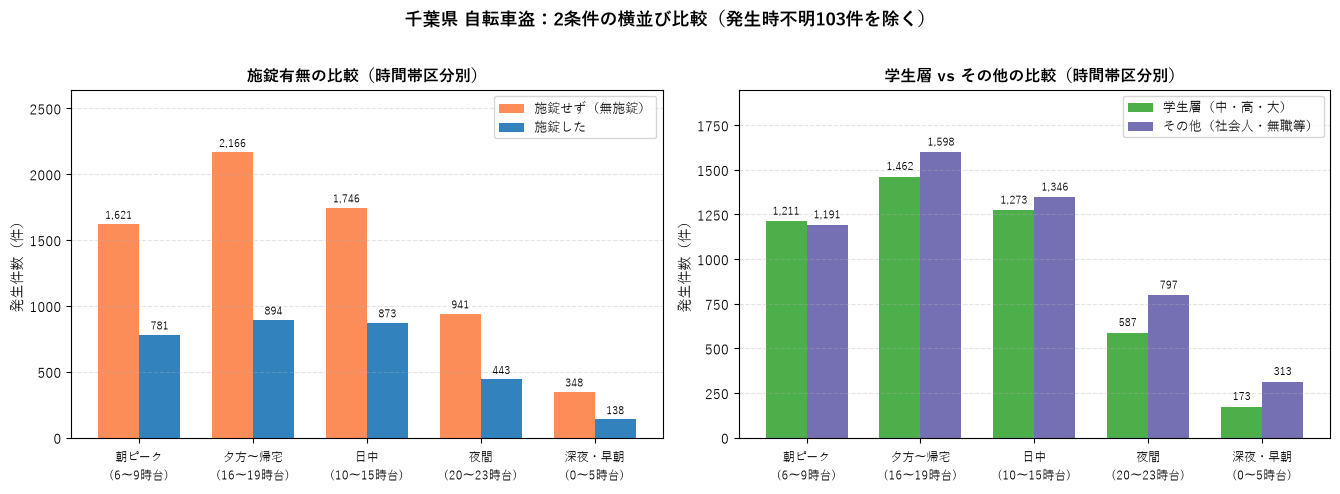

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Colab等で日本語が文字化けする場合は、必要に応じて japanize_matplotlib 等を有効化してください
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "Yu Gothic", "Meiryo", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

if "df" not in globals():
    df = pd.read_csv("bike.csv", encoding="cp932")

valid_h = df.copy()
valid_h["hour_num"] = pd.to_numeric(valid_h["発生時（始期）"], errors="coerce")
valid_h = valid_h.dropna(subset=["hour_num"]).copy()

def bucket_hour(h):
    h = int(h)
    if 0 <= h <= 5:
        return "深夜・早朝\n(0〜5時台)"
    elif 6 <= h <= 9:
        return "朝ピーク\n(6〜9時台)"
    elif 10 <= h <= 15:
        return "日中\n(10〜15時台)"
    elif 16 <= h <= 19:
        return "夕方〜帰宅\n(16〜19時台)"
    return "夜間\n(20〜23時台)"

valid_h["時間帯区分"] = valid_h["hour_num"].apply(bucket_hour)
period_order = [
    "朝ピーク\n(6〜9時台)",
    "夕方〜帰宅\n(16〜19時台)",
    "日中\n(10〜15時台)",
    "夜間\n(20〜23時台)",
    "深夜・早朝\n(0〜5時台)",
]

# 2つの比較条件をここで指定（必要に応じて変更可能）
student_jobs = {"中学生", "高校生", "大学生"}

cond_a_1 = [len(valid_h[(valid_h["時間帯区分"] == p) & (valid_h["施錠関係"] == "施錠せず")]) for p in period_order]
cond_a_2 = [len(valid_h[(valid_h["時間帯区分"] == p) & (valid_h["施錠関係"] == "施錠した")]) for p in period_order]

cond_b_1 = [len(valid_h[(valid_h["時間帯区分"] == p) & (valid_h["被害者の職業"].isin(student_jobs))]) for p in period_order]
cond_b_2 = [len(valid_h[(valid_h["時間帯区分"] == p) & (~valid_h["被害者の職業"].isin(student_jobs))]) for p in period_order]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
x = np.arange(len(period_order))
width = 0.36

# 左グラフ：施錠有無の比較
bars_a1 = axes[0].bar(x - width / 2, cond_a_1, width=width, label="施錠せず（無施錠）", color="#fc8d59")
bars_a2 = axes[0].bar(x + width / 2, cond_a_2, width=width, label="施錠した", color="#3182bd")
axes[0].set_title("施錠有無の比較（時間帯区分別）", fontsize=11.5, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(period_order, fontsize=8.8)
axes[0].set_ylabel("発生件数（件）")
axes[0].grid(axis="y", linestyle="--", alpha=0.35)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].set_ylim(0, max(max(cond_a_1), max(cond_a_2)) * 1.22)

for bars in (bars_a1, bars_a2):
    for bar in bars:
        val = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            val + 30,
            f"{int(val):,}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

# 右グラフ：学生層 vs その他の比較
bars_b1 = axes[1].bar(x - width / 2, cond_b_1, width=width, label="学生層（中・高・大）", color="#4daf4a")
bars_b2 = axes[1].bar(x + width / 2, cond_b_2, width=width, label="その他（社会人・無職等）", color="#7570b3")
axes[1].set_title("学生層 vs その他の比較（時間帯区分別）", fontsize=11.5, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(period_order, fontsize=8.8)
axes[1].set_ylabel("発生件数（件）")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(loc="upper right", fontsize=9)
axes[1].set_ylim(0, max(max(cond_b_1), max(cond_b_2)) * 1.22)

for bars in (bars_b1, bars_b2):
    for bar in bars:
        val = bar.get_height()
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            val + 30,
            f"{int(val):,}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.suptitle("千葉県 自転車盗：2条件の横並び比較（発生時不明103件を除く）", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()